In [1]:
import itertools
import numpy as np
import pandas as pd
import glob, os
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D   


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
ls

bi-encoder_BAAI-bge-large-en-v1.5.csv
bi-encoder_Qwen-Qwen3-Embedding-0.6B.csv
bi-encoder_Qwen-Qwen3-Embedding-4B.csv
bi-encoder_Qwen-Qwen3-Embedding-8B.csv
bi-encoder_sentence-transformers-all-MiniLM-L6-v2.csv
colbert_colbert-ir-colbertv2.0.csv
colbert_lightonai-Reason-ModernColBERT.csv
colbert_LiquidAI-LFM2-ColBERT-350M.csv
colbert_mixedbread-ai-mxbai-colbert-large-v1.csv
cross-encoder_BAAI-bge-reranker-v2-m3.csv
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2.csv
cross-encoder_Qwen-Qwen3-Reranker-0.6B.csv
cross-encoder_Qwen-Qwen3-Reranker-4B.csv
cross-encoder_Qwen-Qwen3-Reranker-8B.csv
Medmcqa - Gap cut-off Calibration & Analyser.ipynb


In [3]:
from math import comb
print(comb(7, 3)) 
print(comb(7, 4)) 
print(comb(7, 5)) 
print(comb(7, 6)) 
print(comb(7, 7))

35
35
21
7
1


In [4]:
def load_scores(path):
    df = pd.read_csv(path)
    S = df.filter(regex=r"_score$").drop(columns=["max_score", "median_score"])
    return df, S

files = sorted(f for f in glob.glob("*.csv")
               if f.startswith(("bi-encoder_", "colbert_", "cross-encoder_")))
print(len(files), "files found")      

14 files found


In [5]:
def average_cutoffs(scores, ks=range(3, 8), percentile=90, show=False):
    number_of_specialists = scores.shape[1]            # 7
    average_cutoff_for_k = {}

    for k in ks:
        cutoffs_for_this_k = []
        for i, chosen_columns in enumerate(itertools.combinations(range(number_of_specialists), k)):
            chosen_scores = scores.iloc[:, list(chosen_columns)]
            best_score   = chosen_scores.max(axis=1)
            median_score = chosen_scores.median(axis=1)
            gap = best_score - median_score
            cutoffs_for_this_k.append(gap.quantile(percentile / 100))
        average_cutoff_for_k[k] = sum(cutoffs_for_this_k) / len(cutoffs_for_this_k)

    return pd.DataFrame([average_cutoff_for_k], index=["Average cutoff"]).rename_axis("k", axis=1)

In [7]:
# 2. then the loop over the 14 model files

files = sorted(f for f in glob.glob("*.csv")
               if f.startswith(("bi-encoder_", "colbert_", "cross-encoder_")))

percentiles = [90]
all_rows = []

for file_name in files:
    df, scores = load_scores(file_name)
    assert scores.shape == (100, 7), (file_name, scores.shape)
    for p in percentiles:
        table = average_cutoffs(scores, percentile=p)
        table.insert(0, "model", file_name.replace(".csv", ""))
        table.insert(1, "percentile", p)
        all_rows.append(table)

average_cutoff_table = pd.concat(all_rows, ignore_index=True)
average_cutoff_table

k,model,percentile,3,4,5,6,7
0,bi-encoder_BAAI-bge-large-en-v1.5,90,0.052561,0.057749,0.063553,0.067197,0.068875
1,bi-encoder_Qwen-Qwen3-Embedding-0.6B,90,0.094612,0.101628,0.110051,0.115756,0.122438
2,bi-encoder_Qwen-Qwen3-Embedding-4B,90,0.074752,0.080015,0.086991,0.089667,0.090470
3,bi-encoder_Qwen-Qwen3-Embedding-8B,90,0.082239,0.089704,0.104682,0.107679,0.119947
4,bi-encoder_sentence-transformers-all-MiniLM-L6-v2,90,0.096245,0.101519,0.112716,0.115371,0.124084
5,colbert_LiquidAI-LFM2-ColBERT-350M,90,0.001136,0.001287,0.001417,0.001511,0.001565
6,colbert_colbert-ir-colbertv2.0,90,0.072389,0.075687,0.085084,0.090477,0.091252
7,colbert_lightonai-Reason-ModernColBERT,90,0.025477,0.028626,0.033344,0.037591,0.041119
8,colbert_mixedbread-ai-mxbai-colbert-large-v1,90,0.092938,0.099788,0.109684,0.114653,0.113255
9,cross-encoder_BAAI-bge-reranker-v2-m3,90,0.000070,0.000090,0.000114,0.000129,0.000152


bi-encoder_BAAI-bge-large-en-v1.5  p=90
   measured: [0.0526 0.0577 0.0636 0.0672 0.0689]
   fitted:   [0.0526 0.0584 0.0629 0.0665 0.0696]
   c0=0.0304  c1=0.0202  R2=0.990

bi-encoder_Qwen-Qwen3-Embedding-0.6B  p=90
   measured: [0.0946 0.1016 0.1101 0.1158 0.1224]
   fitted:   [0.0935 0.103  0.1103 0.1163 0.1214]
   c0=0.0574  c1=0.0329  R2=0.991

bi-encoder_Qwen-Qwen3-Embedding-4B  p=90
   measured: [0.0748 0.08   0.087  0.0897 0.0905]
   fitted:   [0.0751 0.0808 0.0852 0.0889 0.0919]
   c0=0.0532  c1=0.0199  R2=0.964

bi-encoder_Qwen-Qwen3-Embedding-8B  p=90
   measured: [0.0822 0.0897 0.1047 0.1077 0.1199]
   fitted:   [0.0803 0.0929 0.1027 0.1107 0.1175]
   c0=0.0321  c1=0.0439  R2=0.963

bi-encoder_sentence-transformers-all-MiniLM-L6-v2  p=90
   measured: [0.0962 0.1015 0.1127 0.1154 0.1241]
   fitted:   [0.0947 0.1041 0.1114 0.1173 0.1224]
   c0=0.0588  c1=0.0327  R2=0.965

colbert_LiquidAI-LFM2-ColBERT-350M  p=90
   measured: [0.0011 0.0013 0.0014 0.0015 0.0016]
   fitted:   

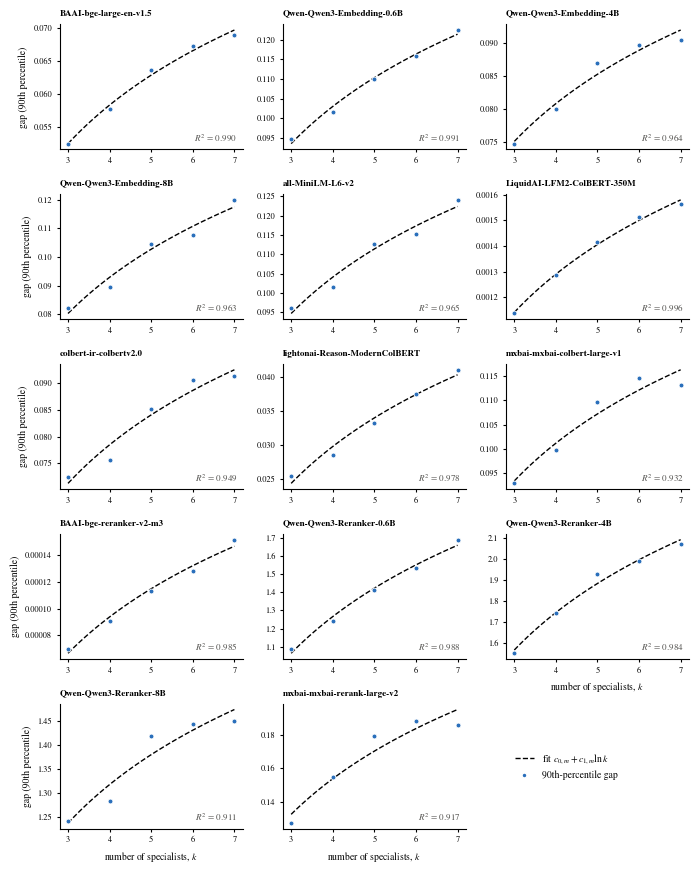

,model,percentile,c0,c1,R2
0,bi-encoder_BAAI-bge-large-en-v1.5,90,0.030415,0.020155,0.989762
1,bi-encoder_Qwen-Qwen3-Embedding-0.6B,90,0.057401,0.032875,0.990758
2,bi-encoder_Qwen-Qwen3-Embedding-4B,90,0.053238,0.019881,0.964209
3,bi-encoder_Qwen-Qwen3-Embedding-8B,90,0.032083,0.043901,0.962859
4,bi-encoder_sentence-transformers-all-MiniLM-L6-v2,90,0.058811,0.032671,0.964504
5,colbert_LiquidAI-LFM2-ColBERT-350M,90,0.000571,0.000518,0.995835
6,colbert_colbert-ir-colbertv2.0,90,0.043856,0.024976,0.949024
7,colbert_lightonai-Reason-ModernColBERT,90,0.003726,0.018837,0.977632
8,colbert_mixedbread-ai-mxbai-colbert-large-v1,90,0.063783,0.026992,0.931777
9,cross-encoder_BAAI-bge-reranker-v2-m3,90,-0.000038,0.000095,0.984656


In [10]:
# 3. Finding c0 and c1  (MedMCQA: 7 specialists, so pool sizes k = 3 ... 7)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ks = np.arange(3, 8)                     # the pool sizes: 3, 4, 5, 6, 7
rows = []                                # one result per (model, percentile)
fits = {}

# each row of the table = one model at one percentile, with five measured numbers (k = 3 ... 7)
for row_number, row in average_cutoff_table[average_cutoff_table["percentile"] == 90].iterrows():

    model_name = row["model"]
    percentile = row["percentile"]

    # the five measured cutoffs of this row
    measured = row[[3, 4, 5, 6, 7]].astype(float).values

    # fit the line  measured = c0 + c1 * ln(k)
    c1, c0 = np.polyfit(np.log(ks), measured, 1)

    fitted = c0 + c1 * np.log(ks)
    r2 = 1 - ((measured - fitted) ** 2).sum() / ((measured - measured.mean()) ** 2).sum()

    print(f"{model_name}  p={percentile}")
    print(f"   measured: {np.round(measured, 4)}")
    print(f"   fitted:   {np.round(fitted, 4)}")
    print(f"   c0={c0:.4f}  c1={c1:.4f}  R2={r2:.3f}\n")

    rows.append({"model": model_name, "percentile": percentile,
                 "c0": c0, "c1": c1, "R2": r2})
    fits[model_name] = (measured, c0, c1, r2)

constants = pd.DataFrame(rows)
constants.to_csv("medmcqa_constants.csv", index=False)


# ---- figure: one panel per model ----
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7,
                     "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 7})

BLUE = "#2a6fbb"

def short_name(file_name):
    name = file_name.replace(".csv", "").split("_", 1)[1]           
    return name.replace("sentence-transformers-", "").replace("mixedbread-ai-", "mxbai-")

n_cols = 3
n_rows = int(np.ceil((len(fits) + 1) / n_cols))                    

fine_k = np.linspace(3, 7, 100)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.0, 1.75 * n_rows))
axes = axes.ravel()

for ax, (f, (tau, c0, c1, r2)) in zip(axes, fits.items()):
    ax.plot(fine_k, c0 + c1 * np.log(fine_k), "--", color="black", lw=1.0)
    ax.plot(ks, tau, "o", color=BLUE, ms=3.5, mec="white", mew=0.6)
    ax.set_title(short_name(f), loc="left", fontsize=6.5, fontweight="bold")
    ax.set_xticks(ks)
    ax.tick_params(length=2)
    ax.text(0.97, 0.06, f"$R^2$ = {r2:.3f}", transform=ax.transAxes,
            ha="right", fontsize=6.5, color="#52514e")
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[len(fits):]:                                        
    ax.axis("off")

# legend in the first empty panel
spare = axes[len(fits)]
handles = [plt.Line2D([0], [0], ls="--", color="black", lw=1,
                      label=r"fit $c_{0,m}+c_{1,m}\ln k$"),
           plt.Line2D([0], [0], marker="o", ls="", color=BLUE, ms=3.5, mec="white",
                      label="90th-percentile gap")]
spare.legend(handles=handles, frameon=False, loc="center left")

for ax in axes[len(fits) - n_cols:len(fits)]:                       
    ax.set_xlabel("number of specialists, $k$")
for r in range(n_rows):
    axes[r * n_cols].set_ylabel("gap (90th percentile)")

fig.tight_layout(w_pad=1.0, h_pad=1.0)
fig.savefig("cutoff_fit_all_medmcqa.pdf", bbox_inches="tight")
fig.savefig("cutoff_fit_all_medmcqa.png", dpi=600, bbox_inches="tight")
plt.show()

constants